In [ ]:
import pandas as pd
import numpy as np

# Membuat dataset simulasi konsumsi energi
np.random.seed(42)
n_rows = 1000

dates = pd.date_range(start="2025-01-01", periods=n_rows, freq="H")
temperature = np.random.normal(loc=28, scale=5, size=n_rows) # Suhu luar (°C)
humidity = np.random.uniform(40, 90, size=n_rows) # Kelembaban (%)
is_weekend = dates.dayofweek.isin([5, 6]).astype(int)

hour = dates.hour
base_load = 50
temp_effect = np.maximum(0, (temperature - 25) * 3)
hour_effect = 10 * np.sin(hour * np.pi / 12)
weekend_effect = -15 * is_weekend

energy_consumption = base_load + temp_effect + hour_effect + weekend_effect + np.random.normal(0, 5, size=n_rows)

df_energy = pd.DataFrame({
    'Timestamp': dates,
    'Temperature': temperature,
    'Humidity': humidity,
    'Is_Weekend': is_weekend,
    'Hour': hour,
    'Energy_Consumption': energy_consumption
})

# Simpan ke file CSV agar otomatis masuk ke folder Colab
df_energy.to_csv('energy_consumption_data.csv', index=False)
print("File 'energy_consumption_data.csv' berhasil dibuat di folder Colab!")

File 'energy_consumption_data.csv' berhasil dibuat di folder Colab!


/tmp/ipykernel_1251/1422629907.py:8: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  dates = pd.date_range(start="2025-01-01", periods=n_rows, freq="H")


In [2]:
# 1. Load dataset yang sudah dibuat
df = pd.read_csv('energy_consumption_data.csv')

# 2. Ubah kolom Timestamp kembali menjadi format datetime Pandas
df['Timestamp'] = pd.to_datetime(df['Timestamp'])

# 3. Ekstrak informasi bulan dan hari dalam seminggu (Feature Engineering)
df['Month'] = df['Timestamp'].dt.month
df['DayOfWeek'] = df['Timestamp'].dt.dayofweek

# 4. Memisahkan variabel independen (X = Fitur/Prediktor) dan dependen (y = Target)
# Kolom 'Timestamp' dan 'Energy_Consumption' dibuang dari X karena Timestamp bukan fitur numerik langsung, dan Energy_Consumption adalah target yang mau diprediksi.
X = df.drop(columns=['Timestamp', 'Energy_Consumption'])
y = df['Energy_Consumption']

In [3]:
from sklearn.model_selection import train_test_split

# Membagi data dengan rasio 80:20
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Jumlah baris data untuk belajar (Training): {X_train.shape[0]}")
print(f"Jumlah baris data untuk ujian (Testing): {X_test.shape[0]}")

Jumlah baris data untuk belajar (Training): 800
Jumlah baris data untuk ujian (Testing): 200


In [4]:
from sklearn.ensemble import RandomForestRegressor

# Memanggil model Random Forest
model = RandomForestRegressor(n_estimators=100, random_state=42)

# Melatih model menggunakan data training (X_train dan y_train)
model.fit(X_train, y_train)

print("Model Machine Learning berhasil dilatih!")

Model Machine Learning berhasil dilatih!


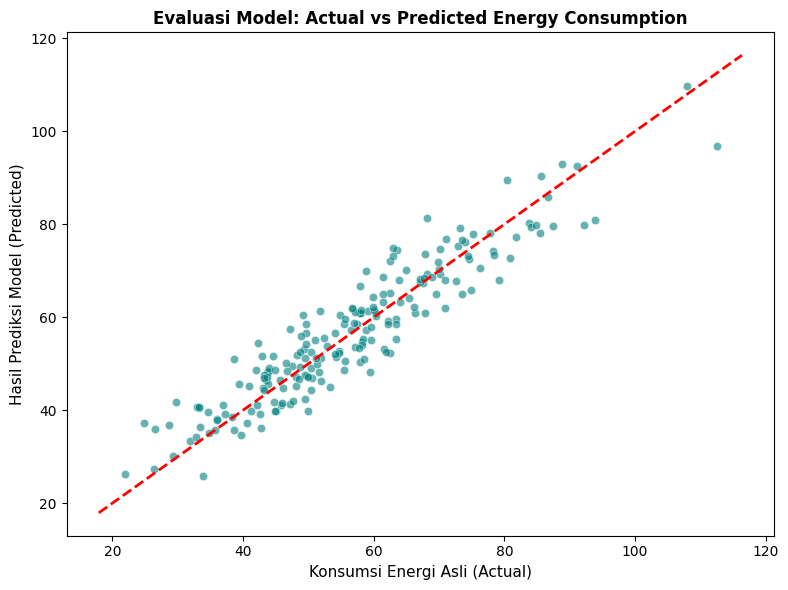

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Menghasilkan prediksi menggunakan model yang sudah dilatih
y_pred = model.predict(X_test)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6, color='teal')
plt.xlabel("Konsumsi Energi Asli (Actual)", fontsize=11)
plt.ylabel("Hasil Prediksi Model (Predicted)", fontsize=11)
plt.title("Evaluasi Model: Actual vs Predicted Energy Consumption", fontsize=12, fontweight='bold')

# Garis diagonal ideal (jika tebakan model 100% pas)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2)
plt.tight_layout()

# Menyimpan gambar grafik
plt.savefig('energy_prediction_result.png', dpi=300, bbox_inches='tight')
plt.show()